In [1]:
import pygad
import pickle
import funciones 

In [2]:
ga_instancia_inconsistencia_10k = pygad.load("./experimento1/resultado10k/instancia_10k_inconsistencia_cpp")
ga_instancia_inconsistencia_100k = pygad.load("./experimento1/resultado100k/instancia_100k_inconsistencia_cpp")
ga_instancia_inconsistencia_750k = pygad.load("./experimento1/resultado750k/instancia_750k_inconsistencia_cpp")

ga_instancia_inconsistencia_hibrida_10k = pygad.load("./experimento1/resultado10k/instancia_10k_hibrida_cpp")
ga_instancia_inconsistencia_hibrida_100k = pygad.load("./experimento1/resultado100k/instancia_100k_hibrida_cpp")
ga_instancia_inconsistencia_hibrida_750k = pygad.load("./experimento1/resultado750k/instancia_750k_hibrida_cpp")

ga_instancia_wrapped_10k = pygad.load("./experimento1/resultado10k/instancia_10k_wrapped_lgb")
ga_instancia_wrapped_100k = pygad.load("./experimento1/resultado100k/instancia_100k_wrapped_lgb")
ga_instancia_wrapped_750k = pygad.load("./experimento1/resultado750k/instancia_750k_wrapped_lgb")

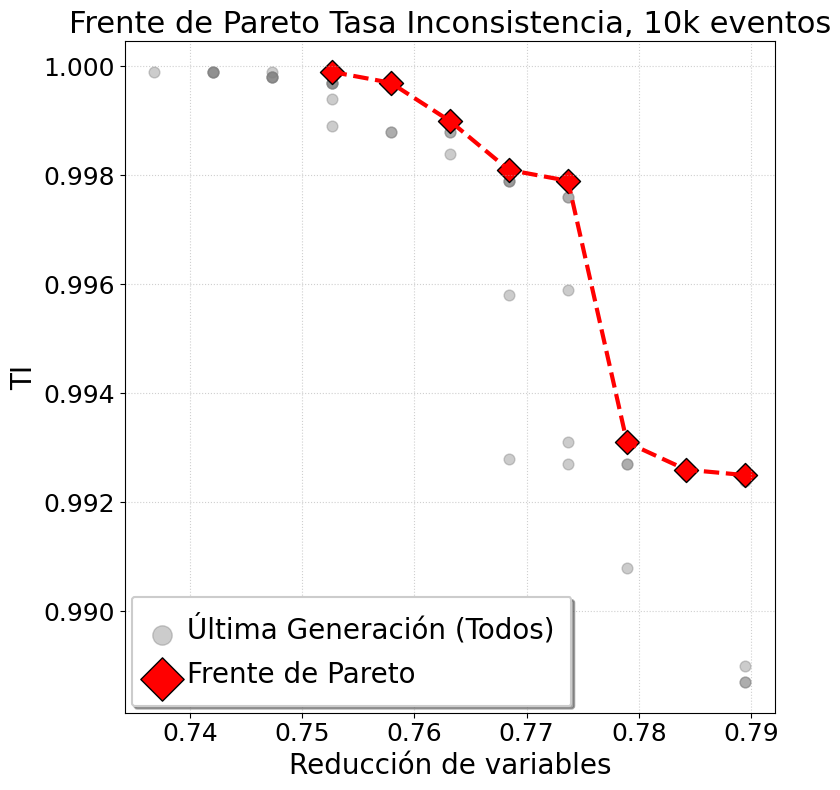

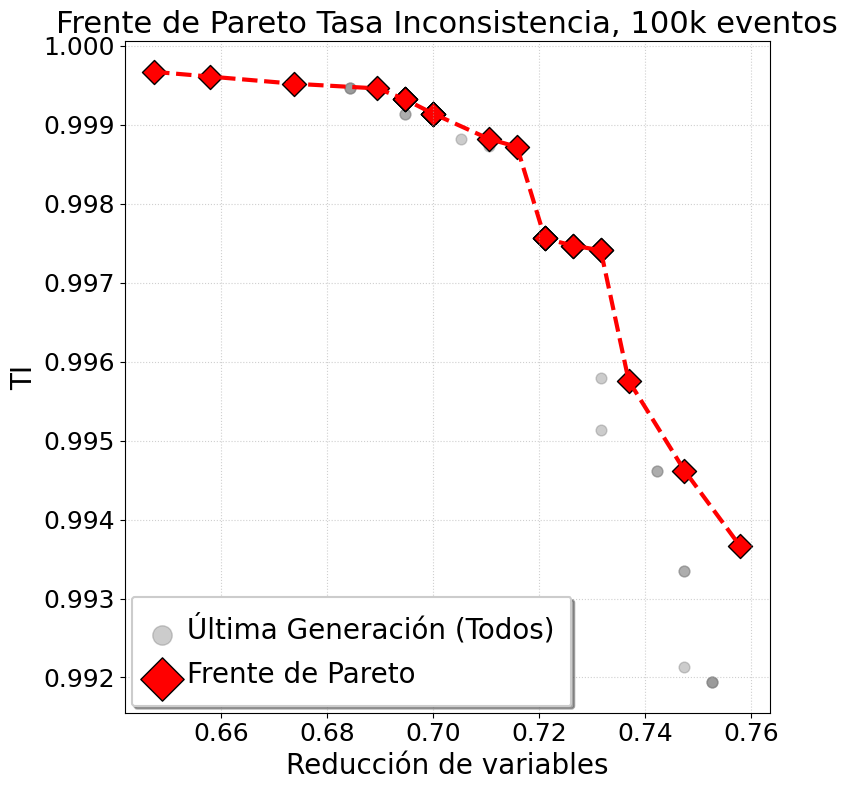

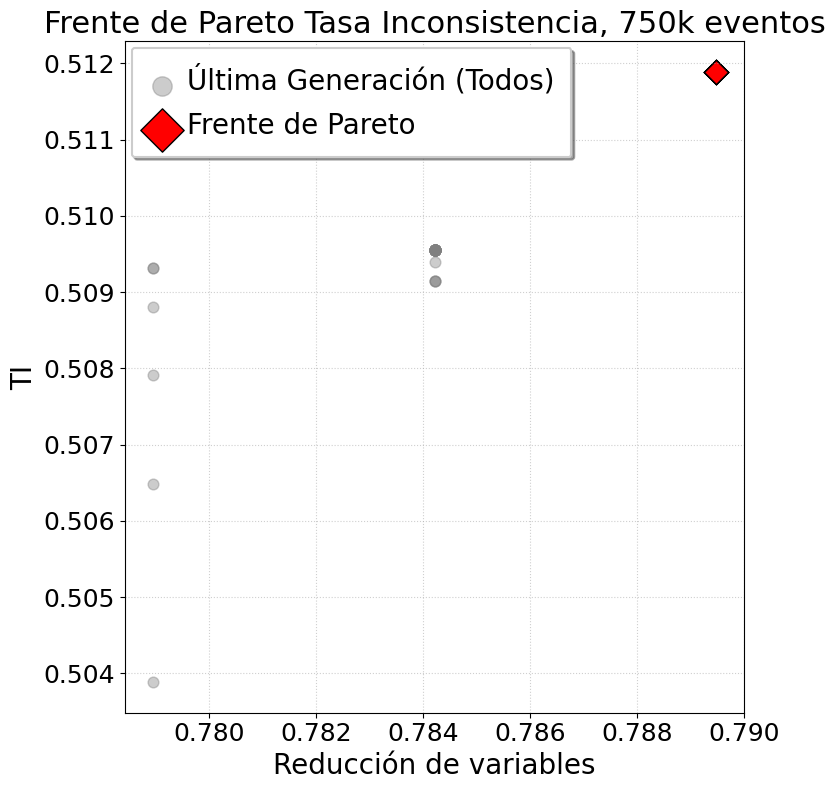

In [4]:
#FRente de Pareto Inconsistencia normal

funciones.frente_pareto(ga_instancia_inconsistencia_10k, 'Frente de Pareto Tasa Inconsistencia, 10k eventos',  'Reducción de variables', 'TI')
funciones.frente_pareto(ga_instancia_inconsistencia_100k, 'Frente de Pareto Tasa Inconsistencia, 100k eventos',  'Reducción de variables', 'TI')
funciones.frente_pareto(ga_instancia_inconsistencia_hibrida_750k, 'Frente de Pareto Tasa Inconsistencia, 750k eventos',  'Reducción de variables', 'TI')

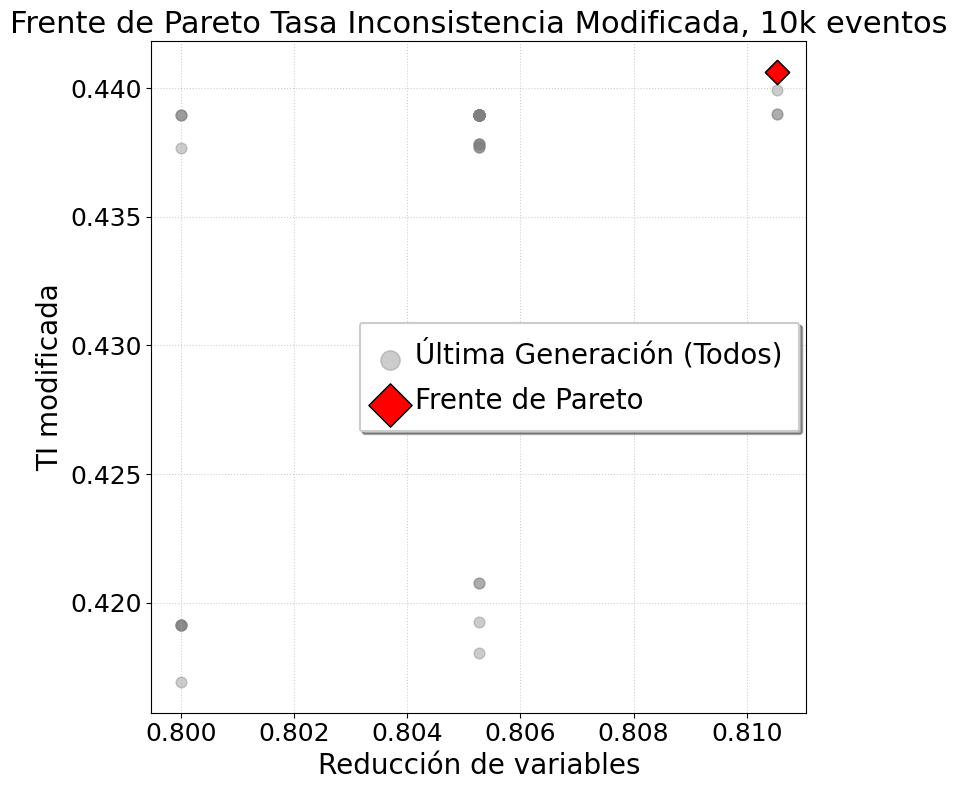

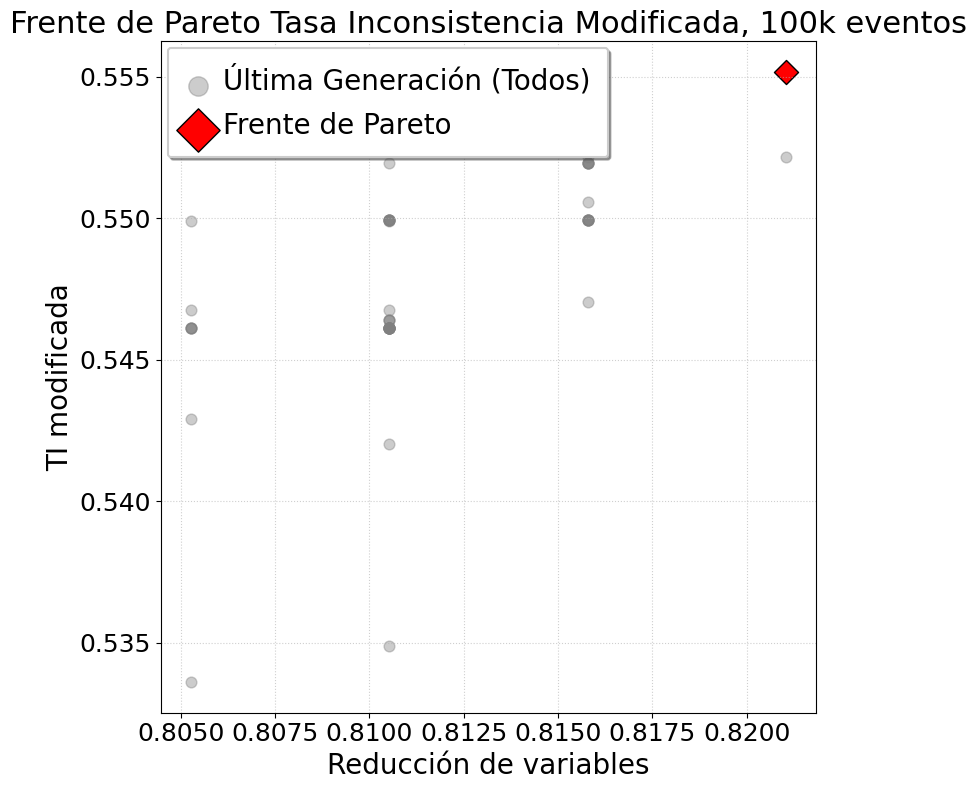

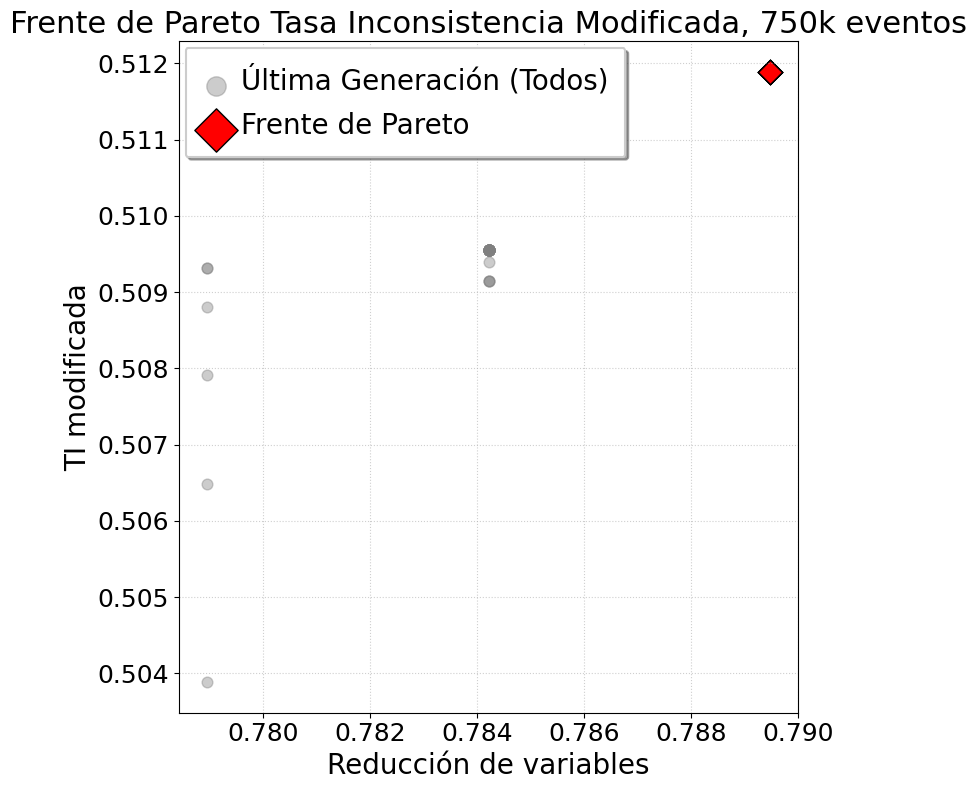

In [5]:
#Frente de pareto Inconsistencia hibrida

funciones.frente_pareto(ga_instancia_inconsistencia_hibrida_10k, 'Frente de Pareto Tasa Inconsistencia Modificada, 10k eventos',  'Reducción de variables', 'TI modificada')
funciones.frente_pareto(ga_instancia_inconsistencia_hibrida_100k, 'Frente de Pareto Tasa Inconsistencia Modificada, 100k eventos',  'Reducción de variables', 'TI modificada')
funciones.frente_pareto(ga_instancia_inconsistencia_hibrida_750k, 'Frente de Pareto Tasa Inconsistencia Modificada, 750k eventos',  'Reducción de variables', 'TI modificada')

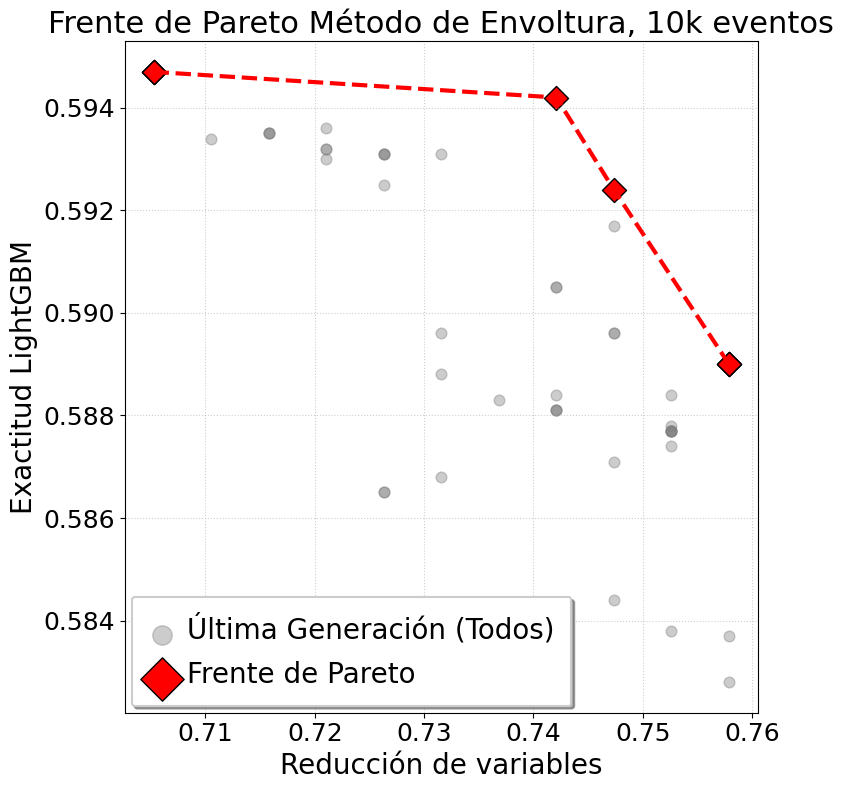

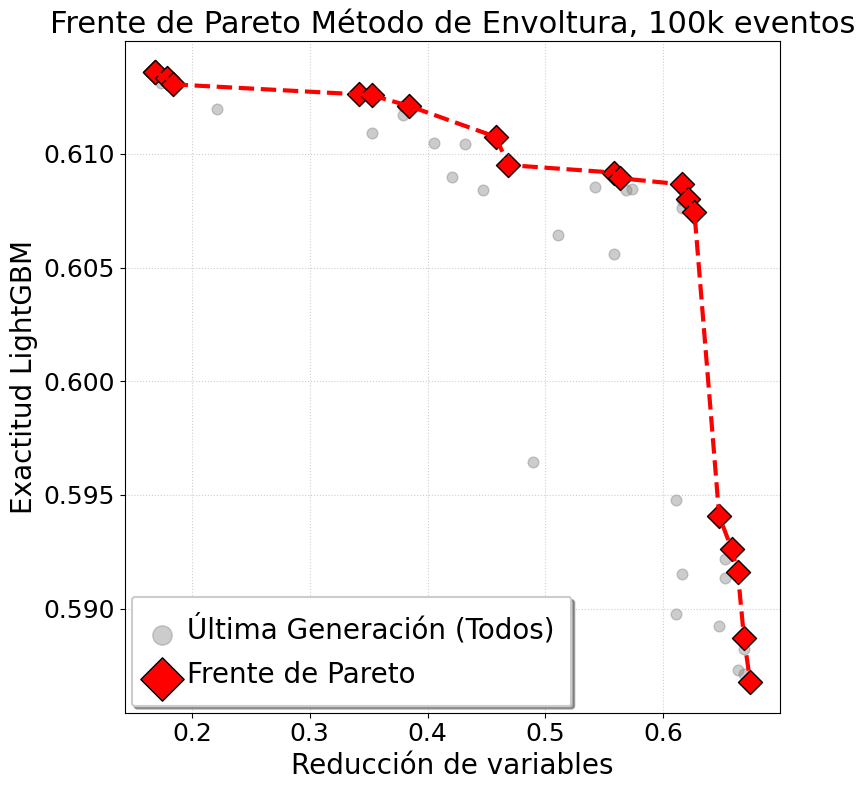

In [6]:
#Frente de pareto WRAPPED

funciones.frente_pareto(ga_instancia_wrapped_10k, 'Frente de Pareto Método de Envoltura, 10k eventos',  'Reducción de variables', 'Exactitud LightGBM')
funciones.frente_pareto(ga_instancia_wrapped_100k, 'Frente de Pareto Método de Envoltura, 100k eventos',  'Reducción de variables', 'Exactitud LightGBM')

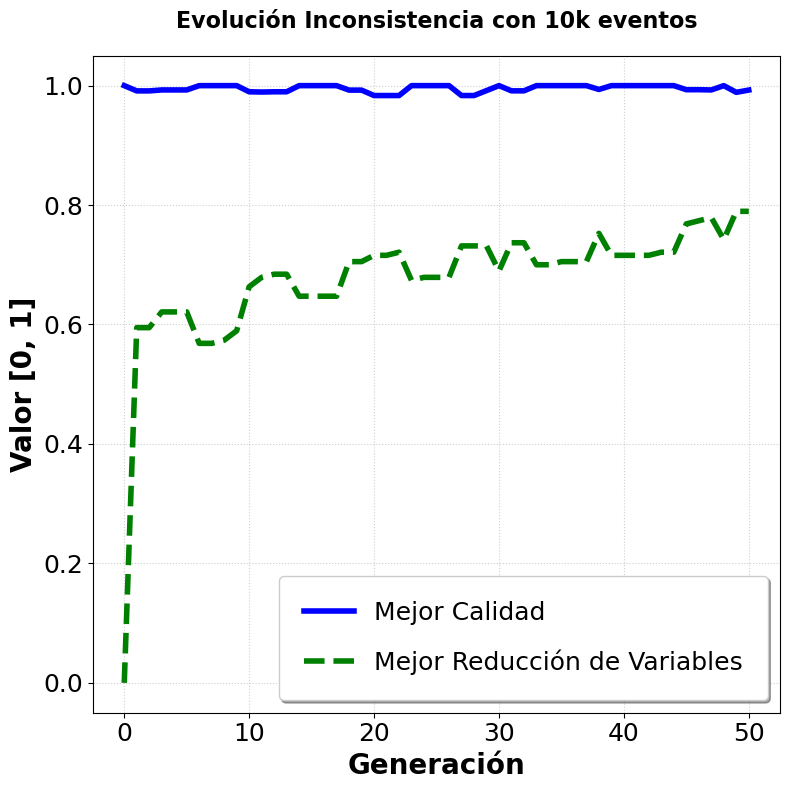

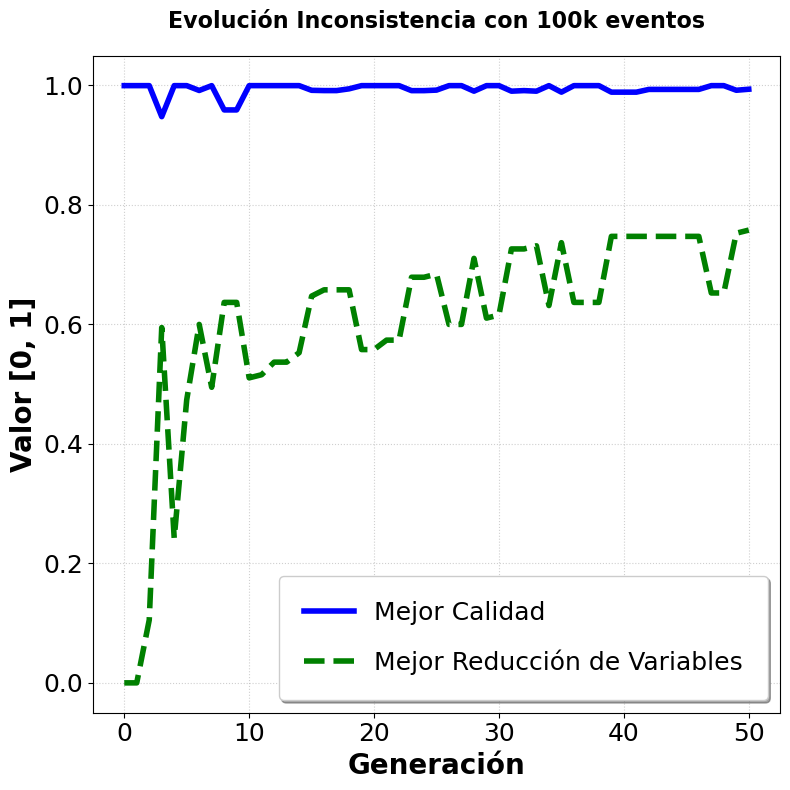

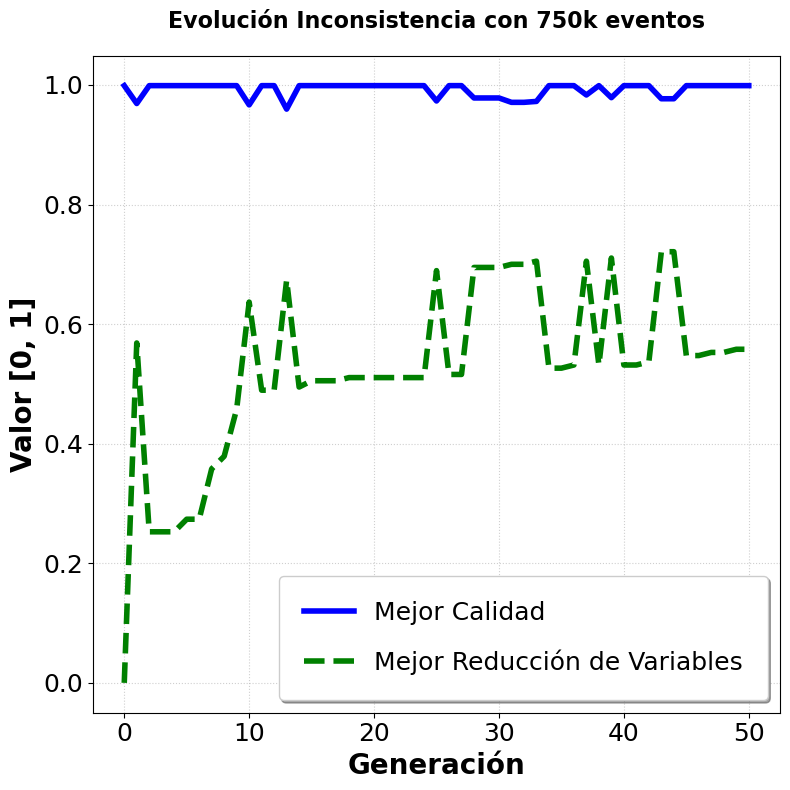

In [7]:
funciones.evolucion(ga_instancia_inconsistencia_10k, 'Evolución Inconsistencia con 10k eventos')
funciones.evolucion(ga_instancia_inconsistencia_100k, 'Evolución Inconsistencia con 100k eventos')
funciones.evolucion(ga_instancia_inconsistencia_750k, 'Evolución Inconsistencia con 750k eventos')

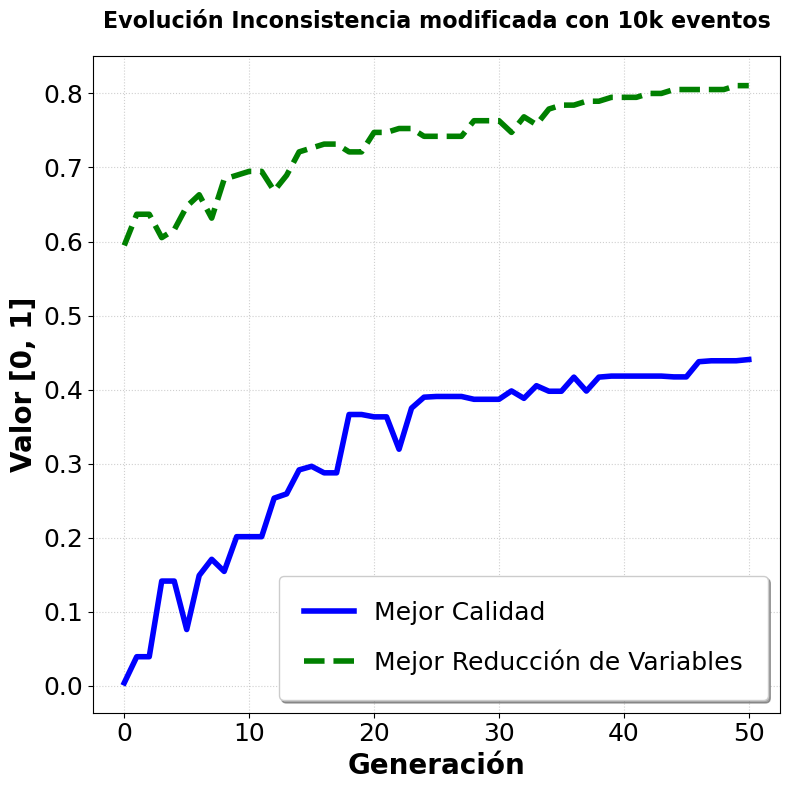

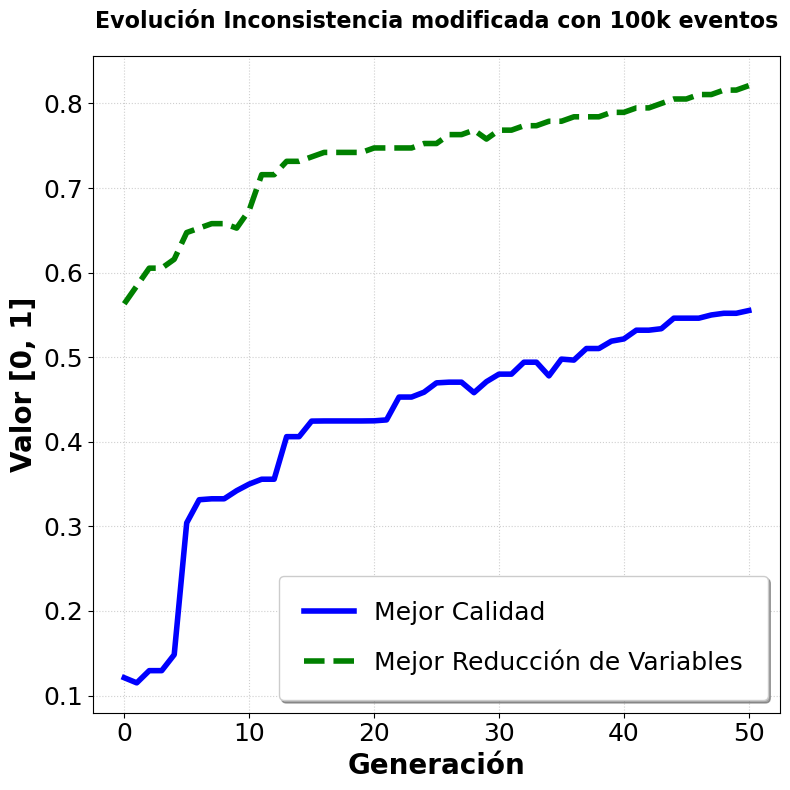

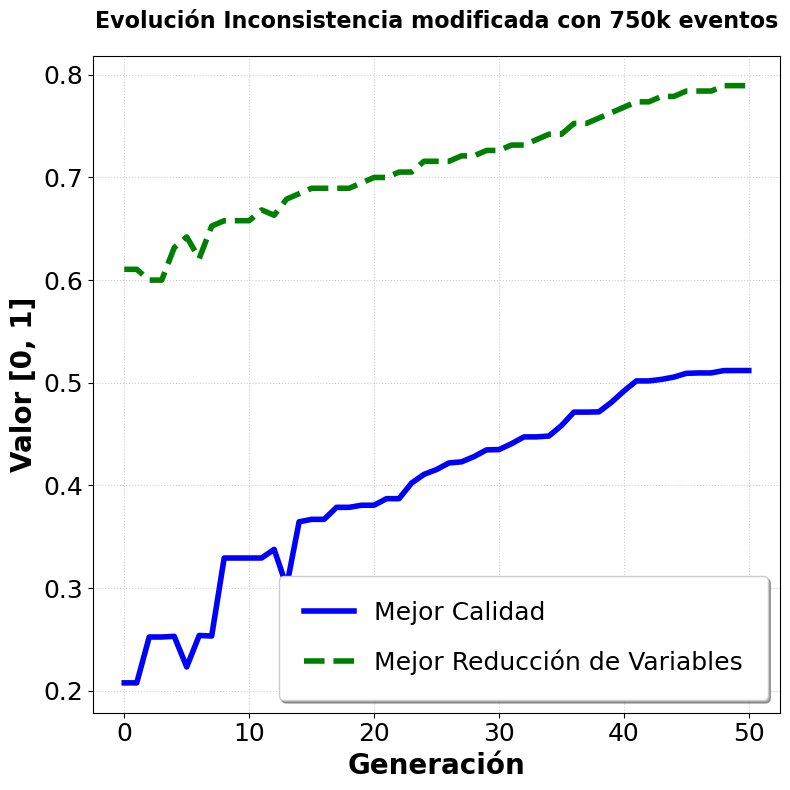

In [8]:
funciones.evolucion(ga_instancia_inconsistencia_hibrida_10k, 'Evolución Inconsistencia modificada con 10k eventos')
funciones.evolucion(ga_instancia_inconsistencia_hibrida_100k, 'Evolución Inconsistencia modificada con 100k eventos')
funciones.evolucion(ga_instancia_inconsistencia_hibrida_750k, 'Evolución Inconsistencia modificada con 750k eventos')

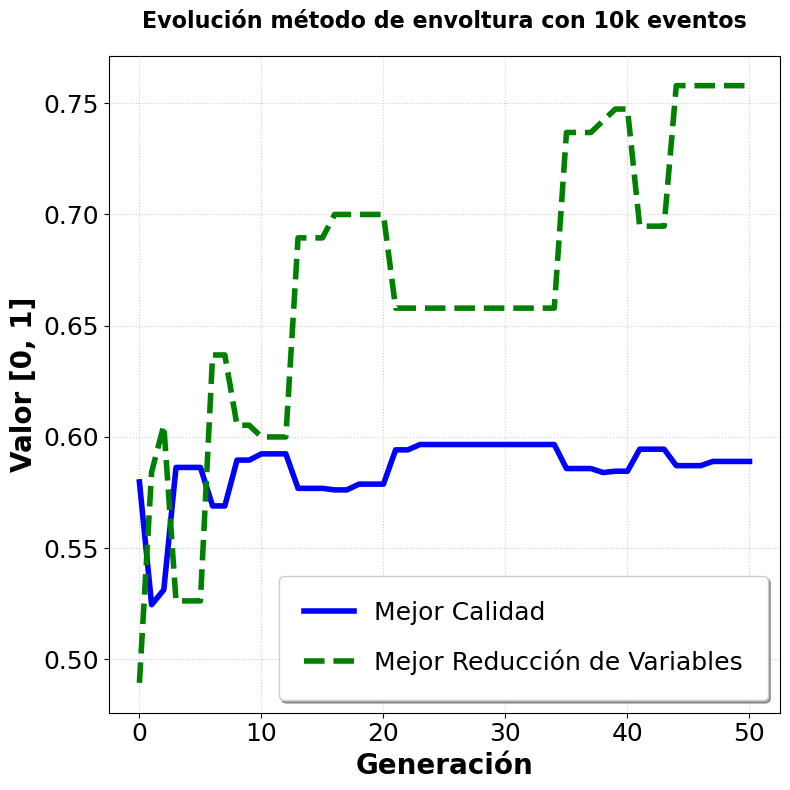

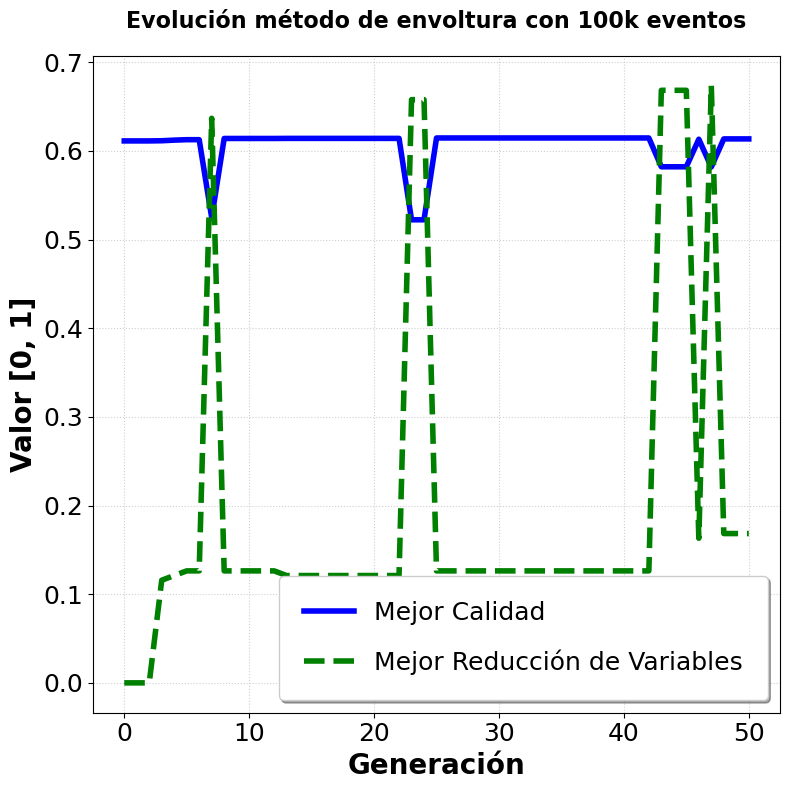

In [9]:
funciones.evolucion(ga_instancia_wrapped_10k, 'Evolución método de envoltura con 10k eventos')
funciones.evolucion(ga_instancia_wrapped_100k, 'Evolución método de envoltura con 100k eventos')

In [9]:
#KNEE POINT
from kneed import KneeLocator
from ejecucion_AG_TI import mutation_func, fitness_exp, callback_generacion
ruta= './experimento1/resultado100k/resumen_100k_wrapped_lgb.pkl'
with open(ruta, 'rb') as f:
    resumen_100k_wrapped = pickle.load(f)



resumen_100k_wrapped.keys()
fitness_total = resumen_100k_wrapped['fitness_final'] #fitness de toda la ultima generacion
poblacion_total = resumen_100k_wrapped['poblacion_final']


In [10]:
import numpy as np

# Obtener frente de pareto a partir de la ultima poblacion guardada en el resumen del experimento
def obtener_fitness_pareto(fitness_scores):
    """Filtra los individuos para quedarse solo con el Frente de Pareto"""
    n_puntos = fitness_scores.shape[0]
    es_pareto = np.ones(n_puntos, dtype=bool)
    
    for i in range(n_puntos):
        for j in range(n_puntos):
            # Si el punto j domina al punto i
            # np.all(..) es true si todos son true. np.any(...) estrue si al menos uno es true
            if np.all(fitness_scores[j] >= fitness_scores[i]) and np.any(fitness_scores[j] > fitness_scores[i]):
                es_pareto[i] = False
                break
    
    return fitness_scores[es_pareto]

fitnes_pareto = obtener_fitness_pareto(fitness_total)

indices_ordenados = np.argsort(fitnes_pareto[:,1]) #Ordenamiento a traves del eje X
x_data = fitnes_pareto[indices_ordenados, 1]
y_data = fitnes_pareto[indices_ordenados, 0]

kneedle = KneeLocator(x_data, y_data, 
                      S= 1, 
                      curve='concave', 
                      direction='decreasing',
                      online=False,
                      interp_method= 'polynomial')

punto_codo_x = kneedle.knee
punto_codo_y = kneedle.knee_y

print(f"--- Resultado del Algoritmo Kneedle ---")
print(f"Punto de corte (Reducción): {punto_codo_x:.4f}")
print(f"Exactitud en el codo: {punto_codo_y:.4f}")


--- Resultado del Algoritmo Kneedle ---
Punto de corte (Reducción): 0.6579
Exactitud en el codo: 0.5926


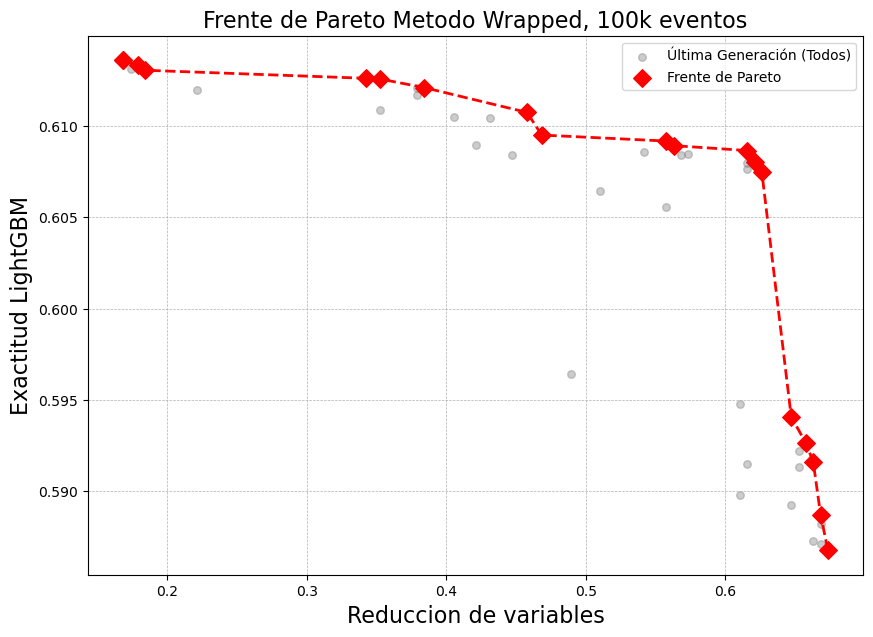

In [11]:
funciones.frente_pareto(ga_instancia_wrapped_100k, 'Frente de Pareto Metodo Wrapped, 100k eventos',  'Reduccion de variables', 'Exactitud LightGBM')

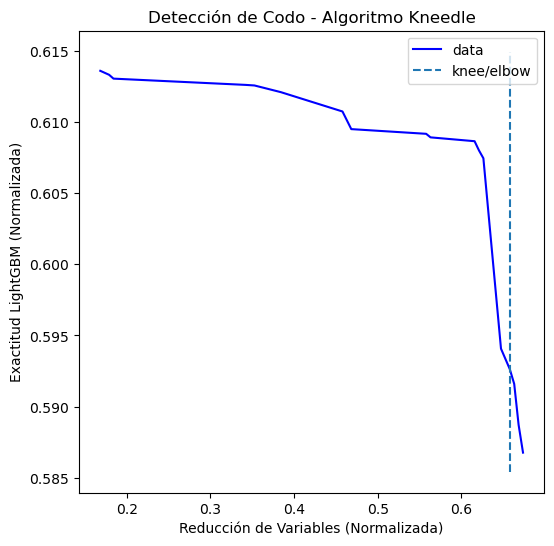

In [12]:
import matplotlib.pyplot as plt

# Esto genera una gráfica con la curva normalizada y el punto detectado
kneedle.plot_knee()
plt.title("Detección de Codo - Algoritmo Kneedle")
plt.xlabel("Reducción de Variables (Normalizada)")
plt.ylabel("Exactitud LightGBM (Normalizada)")
plt.show()

In [13]:
import numpy as np

def seleccionar_codo_punto_utopia(fitness_scores):
    """
    Recibe el fitness de las soluciones del frente de pareto
    Selecciona la mejor solución basada en la distancia al punto ideal (Utopia).
    Basado en Marler & Arora (2004).
    """
    # fitness_scores: Matriz (N, 2) -> Col 0: Exactitud, Col 1: Reducción

    f_max = np.max(fitness_scores, axis=0)
    f_min = np.min(fitness_scores, axis=0)
    
    #Normalizacion
    norm_scores = (fitness_scores - f_min) / (f_max - f_min)
    
    #Punto de utopia
    utopia_normalizada = np.array([1.0, 1.0])
    
    # Distancia euclidiana 
    distancias = np.sqrt(np.sum((norm_scores - utopia_normalizada)**2, axis=1))
    
    #La solucion elegida minimiza la distancia euclidiana.
    idx_mejor = np.argmin(distancias)
    
    return idx_mejor, fitness_scores[idx_mejor]

# Uso con tus datos de Belle II
# x_data y y_data deben ser los valores de tu frente de Pareto
fitness_pareto = np.column_stack((y_data, x_data)) # [Exactitud, Reducción]
idx, mejor_solucion = seleccionar_codo_punto_utopia(fitness_pareto)

print(f"--- Selección por Punto Ideal ---")
print(f"Exactitud: {mejor_solucion[0]:.4f}")
print(f"Reducción: {mejor_solucion[1]:.4f}")

--- Selección por Punto Ideal ---
Exactitud: 0.6087
Reducción: 0.6158


In [14]:
import lightgbm as lgb
import numpy as np

idx_pareto, mejor_individuo = funciones.seleccionar_codo_punto_utopia(fitness_pareto)

mejor_individuo
mejor_exactitud = mejor_individuo[0]
idx_original = np.where(fitness_total[:, 0] == mejor_exactitud)[0][0]

mascara_ganadora = poblacion_total[idx_original]
print(mascara_ganadora)

indices_variables = np.where(mascara_ganadora == 1)[0]

print(indices_variables)

[1 1 1 1 1 0 0 0 1 0 1 1 1 0 1 1 0 0 0 1 0 1 0 1 0 0 1 0 0 1 1 1 1 1 1 1 1
 1 1 1 0 0 1 0 1 0 0 0 1 0 0 1 1 0 0 0 0 1 0 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0
 1 0 0 0 1 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0
 0 1 0 0 1 0 1 0 0 0 1 0 0 1 0 0 1 0 1 0 0 1 1 1 0 1 0 1 0 0 0 1 0 0 0 1 1
 1 1 0 1 0 1 0 0 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 1 1 0 0 0 1 1 0 0 0 1 0 0 0
 0 0 0 0 0]
[  0   1   2   3   4   8  10  11  12  14  15  19  21  23  26  29  30  31
  32  33  34  35  36  37  38  39  42  44  48  51  52  57  60  63  64  70
  72  74  78  84  86  88 100 101 102 104 112 115 117 121 124 127 129 132
 133 134 136 138 142 146 147 148 149 151 153 160 161 164 171 172 176 177
 181]


In [15]:
ruta_experimento= './experimento1/resultado750k/resumen_750k_hibrida.pkl'


len(funciones.extraccion_caracteristicas_compromiso(ruta_experimento))

/home/juan/proyectoTesis/datasets/b-flavor_datos/funciones.py:453: RuntimeWarning: invalid value encountered in divide
  norm_scores = (fitness_scores - f_min) / (f_max - f_min)


40

In [16]:
#Validacion de solucion con un clasificador

X_train_10k_DISC = np.load('./X_train_10k_DISC.npy')
#X_test_10k_DISC = np.load('./X_test_10k_DISC.npy')

X_train_10k = np.load('./X_train_10k_8020.npy')
y_train_10k = np.load('./y_train_10k_8020.npy')
#X_test_10k = np.load('./X_test_10k_8020.npy')
#y_test_10k = np.load('./y_test_10k_8020.npy')

#Para 10k
with open('./experimento1/resultado10k/resumen_10k_inconsistencia.pkl', 'rb') as f:
    resumen_10k_inconsistencia = pickle.load(f)

with open('./experimento1/resultado10k/resumen_10k_hibrida.pkl', 'rb') as f:
    resumen_10k_hibrida = pickle.load(f)

with open('./experimento1/resultado10k/resumen_10k_wrapped_lgb.pkl', 'rb') as f:
    resumen_10k_wrapped = pickle.load(f)

In [17]:
metodo = 'wrapped_lgb' # wrapped_lgb, inconsistencia, hidrida
tipo_datos= 'DISC' # DISC o 8020
path_datos = './resultado10k'
num_instancias = '10k'
experimento = 'experimento1'

X_train = np.load(f'./X_train_{num_instancias}_{tipo_datos}.npy')
y_train = np.load(f'./y_train_{num_instancias}_8020.npy')

nombre_variables_seleccionadas = funciones.extraccion_caracteristicas_compromiso(f'./{experimento}/resultado{num_instancias}/resumen_{num_instancias}_{metodo}.pkl')


In [18]:
#X_validacion = np.load('validation_data.npy', mmap_mode='r')

#with open('validation_data.npy', 'rb') as f:
#    _ = np.load(f)
#    y_validacion = np.load(f)

#print(f"X_validacion shape: {X_validacion.shape}")
#print(f"y_validacion shape: {y_validacion.shape}")

In [19]:
#with open('./nombre_variables_b_flavor.pkl', 'rb') as f:
#    nombre_variables =pickle.load(f)

#nombre_190_variables = nombre_variables['nombre_caracteristicas']
#len(nombre_190_variables)


In [3]:
from lightgbm import LGBMClassifier
import pandas as pd
# --- CONFIGURACIÓN ---
metodo = 'wrapped_lgb' # wrapped_lgb, inconsistencia, hibrida
experimento = 'experimento1'
escalas = ['10k', '100k']

#Cargar nombre de las 190 caracteristicas
with open('./nombre_variables_b_flavor.pkl', 'rb') as f:
    nombre_caracteristicas = pickle.load(f)['nombre_caracteristicas']

# cargar datos de validacion
X_validacion = np.load('validation_data.npy', mmap_mode='r')
with open('validation_data.npy', 'rb') as f:
    _ = np.load(f) # Salto de X
    y_validacion = np.load(f).ravel()

# Diccionario para guardar el reporte final de cada escala
reporte_global = {}
conteo_variables = {}

# --- BUCLE DE ENTRENAMIENTO ---
for num in escalas:
    print(f"\n" + "="*50)
    print(f"PROCESANDO ESCALA: {num}")
    print("="*50)

    #cargar entrenamiento específico
    X_train = np.load(f'./X_train_{num}_8020.npy') 
    y_train = np.load(f'./y_train_{num}_8020.npy').ravel()
    

    #extraer variables ganadoras (Solución de Compromiso / Punto Ideal)
    resumen_path = f'./{experimento}/resultado{num}/resumen_{num}_{metodo}.pkl'
    vars_ganadoras = funciones.extraccion_caracteristicas_compromiso(resumen_path)
    conteo_variables[num] = len(vars_ganadoras)
    #mapear nombres a índices
    indices = [nombre_caracteristicas.index(v) for v in vars_ganadoras]
    
    # Filtrar conjuntos
    X_train_opt = X_train[:, indices]
    X_val_opt = X_validacion[:, indices]

    # Entrenar Modelo
    lgbm = lgb.LGBMClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        n_jobs=-1, # Evita conflictos con la paralelización de PyGAD
        random_state=42,
        verbose=-1
    )
    lgbm.fit(
        X_train_opt, y_train,
        eval_set=[(X_val_opt, y_validacion)],
        eval_metric='auc',
        feature_name=vars_ganadoras,
        callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(period=0)]
    )

    # Evaluar y Graficar
    stats_df, fig = funciones.evaluate_model(lgbm, X_train_opt, y_train, X_val_opt, y_validacion)
    
    # Guardar resultados
    fig.savefig(f'./{experimento}/eval_final_{metodo}_{num}.pdf', bbox_inches='tight')
    reporte_global[num] = stats_df
    plt.close(fig)

print("\n>>> PROCESO COMPLETADO <<<")


resumen_list = []
for num in escalas:
    df_escala = reporte_global[num]
    resumen_escala = {
        'Escala': num,
        'Variables': conteo_variables[num], # <--- Usamos el conteo guardado
        'AUC': df_escala.loc['ROC AUC', 'test'],
        'F1 Max': df_escala.loc['F1 Max', 'test'],
        'Acc Max': df_escala.loc['Exactitud Max', 'test'],
        'APS': df_escala.loc['APS', 'test']
    }
    resumen_list.append(resumen_escala)

df_comparativo = pd.DataFrame(resumen_list).set_index('Escala')

print("\n" + "="*60)
print(f"RESUMEN FINAL PARA EL MÉTODO: {metodo.upper()}")
print("="*60)
print(df_comparativo)

# Código para tu archivo .tex
print("\nTabla para LaTeX:")
print(df_comparativo.to_latex(float_format="%.3f"))

NameError: name 'np' is not defined

In [5]:
import lightgbm as lgb
#from lightgbm import LGBMClassifier
import pandas as pd
import numpy as np
import pickle
import funciones
from ejecucion_AG_TI import mutation_func, fitness_exp, callback_generacion
import matplotlib.pyplot as plt # No olvides este para fig.savefig
# --- CONFIGURACIÓN ---
metodo = 'inconsistencia' # wrapped_lgb, inconsistencia, hibrida
experimento = 'experimento1'
escalas = ['10k', '100k']

#Cargar nombre de las 190 caracteristicas
with open('./nombre_variables_b_flavor.pkl', 'rb') as f:
    nombre_caracteristicas = pickle.load(f)['nombre_caracteristicas']

# cargar datos de validacion
X_validacion = np.load('validation_data.npy', mmap_mode='r')
with open('validation_data.npy', 'rb') as f:
    _ = np.load(f) # Salto de X
    y_validacion = np.load(f).ravel()

# Diccionario para guardar el reporte final de cada escala
reporte_global = {}
conteo_variables = {}

# --- BUCLE DE ENTRENAMIENTO ---
for num in escalas:
    print(f"\n" + "="*50)
    print(f"PROCESANDO ESCALA: {num}")
    print("="*50)

    #cargar entrenamiento específico
    X_train = np.load(f'./X_train_{num}_8020.npy') 
    y_train = np.load(f'./y_train_{num}_8020.npy').ravel()
    

    #extraer variables ganadoras (Solución de Compromiso / Punto Ideal)
    resumen_path = f'./{experimento}/resultado{num}/resumen_{num}_{metodo}.pkl'
    vars_ganadoras = funciones.extraccion_caracteristicas_compromiso(resumen_path)
    conteo_variables[num] = len(vars_ganadoras)
    #mapear nombres a índices
    indices = [nombre_caracteristicas.index(v) for v in vars_ganadoras]
    
    # Filtrar conjuntos
    X_train_opt = X_train[:, indices]
    print(f'Numero de variables de este experimento:{X_train_opt.shape}')
    X_val_opt = X_validacion[:, indices]

    # Entrenar Modelo
    lgbm = lgb.LGBMClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        n_jobs=-1, # Evita conflictos con la paralelización de PyGAD
        random_state=42,
        verbose=-1
    )
    lgbm.fit(
        X_train_opt, y_train,
        eval_set=[(X_val_opt, y_validacion)],
        eval_metric='auc',
        feature_name=vars_ganadoras,
        callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(period=0)]
    )

    # Evaluar y Graficar
    stats_df, fig = funciones.evaluate_model(lgbm, X_train_opt, y_train, X_val_opt, y_validacion)
    
    # Guardar resultados
    fig.savefig(f'./{experimento}/eval_final_{metodo}_{num}.pdf', bbox_inches='tight')
    reporte_global[num] = stats_df
    plt.close(fig)

print("\n>>> PROCESO COMPLETADO <<<")



PROCESANDO ESCALA: 10k
Numero de variables de este experimento:(10000, 43)


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[14]	valid_0's auc: 0.671971	valid_0's binary_logloss: 0.652279


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.58  0.62
Exactitud Max     0.58  0.62
F1 (0.5)          0.57  0.61
F1 Max            0.67  0.69
APS               0.62  0.66
ROC AUC           0.62  0.67

PROCESANDO ESCALA: 100k
Numero de variables de este experimento:(100000, 54)


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's auc: 0.72157	valid_0's binary_logloss: 0.610481


/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/juan/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


                 train  test
Exactitud (0.5)   0.60  0.65
Exactitud Max     0.60  0.65
F1 (0.5)          0.60  0.65
F1 Max            0.69  0.70
APS               0.67  0.73
ROC AUC           0.66  0.72

>>> PROCESO COMPLETADO <<<


In [10]:
# --- GENERACIÓN DE TABLA RESUMEN INTEGRAL ---
resumen_list = []

for num in escalas:
    df_escala = reporte_global[num]
    
    resumen_escala = {
        'Escala': num,
        'Vars': conteo_variables[num],
        # Métricas de Entrenamiento (para mostrar que aprendió bien)
        'Exactitud_Entrenamiento': df_escala.loc['Exactitud (0.5)', 'train'],
        'Exactitud_Validación' : df_escala.loc['Exactitud (0.5)', 'test'],
        'F1_Entrenamiento' : df_escala.loc['F1 (0.5)', 'train'],
        'F1_Validación' : df_escala.loc['F1 (0.5)', 'test'],
        #'F1_Max_Train': df_escala.loc['F1 Max', 'train'],
        'AUC_Entrenamiento': df_escala.loc['ROC AUC', 'train'],
        'AUC_Validación': df_escala.loc['ROC AUC', 'test'],
        'APS_Entrenamiento': df_escala.loc['APS', 'train'],
        'APS_Validación': df_escala.loc['APS', 'test'],
        #'F1_Max_Entrenamiento': df_escala.loc['F1 Max', 'train'],
        #'F1_Max_Validación': df_escala.loc['F1 Max', 'test'],   # Potencial máximo
        #'Exactitud_Max_Entrenamiento': df_escala.loc['Exactitud Max', 'train'],
        #'Exactitud_Max_Validación': df_escala.loc['Exactitud Max', 'test']
    }
    resumen_list.append(resumen_escala)

df_comparativo = pd.DataFrame(resumen_list).set_index('Escala')

print("\n" + "="*80)
print(f"TABLA COMPARATIVA FINAL: {metodo.upper()}")
print("="*80)
print(df_comparativo)

# Exportar a LaTeX con formato profesional
print("\nCódigo LaTeX para tu Capítulo de Resultados:")
print(df_comparativo.to_latex(float_format="%.3f", 
                             caption=f"Comparativa de rendimiento entrenamiento vs. prueba para el método {metodo}."))


TABLA COMPARATIVA FINAL: INCONSISTENCIA
        Vars  Exactitud_Entrenamiento  Exactitud_Validación  F1_Entrenamiento  \
Escala                                                                          
10k       43                     0.58                  0.62              0.57   
100k      54                     0.60                  0.65              0.60   

        F1_Validación  AUC_Entrenamiento  AUC_Validación  APS_Entrenamiento  \
Escala                                                                        
10k              0.61               0.62            0.67               0.62   
100k             0.65               0.66            0.72               0.67   

        APS_Validación  
Escala                  
10k               0.66  
100k              0.73  

Código LaTeX para tu Capítulo de Resultados:
\begin{table}
\caption{Comparativa de rendimiento entrenamiento vs. prueba para el método inconsistencia.}
\begin{tabular}{lrrrrrrrrr}
\toprule
 & Vars & Exactitud_Entrena

In [ ]:
#LightGBM con todas las variables

